# Pipeline de détection d'anomalies — Dataset Cardiovasculaire
### Projet de Fin d'Études — Master 2 Data Management & IA

**Objectif** : détecter les profils cliniques anormaux (présence de maladie cardiovasculaire) à partir de données patients, en comparant des algorithmes supervisés et non supervisés.

**Dataset** : [Cardiovascular Disease Dataset (Kaggle)](https://www.kaggle.com/datasets/sulianova/cardiovascular-disease-dataset) — 70 000 enregistrements patients, 11 features + 1 variable cible (`cardio`).

**Sommaire**
1. Ingestion des données
2. Analyse exploratoire (EDA)
3. Nettoyage & prétraitement
4. Feature Engineering
5. Gestion du déséquilibre des classes
6. Normalisation et séparation train/test
7. Modélisation — Détection d'anomalies
8. Évaluation et comparaison des modèles
9. Interprétabilité (XAI)
10. Automatisation du pipeline


In [1]:
# Installation des dépendances (décommenter si nécessaire sur Colab)
# !pip install kagglehub scikit-learn xgboost shap imbalanced-learn tensorflow -q
import sys
!{sys.executable} -m pip install kagglehub xgboost shap



[notice] A new release of pip is available: 24.0 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import (
    f1_score, roc_auc_score, confusion_matrix, classification_report,
    precision_score, recall_score, RocCurveDisplay
)
from sklearn.pipeline import Pipeline
import joblib
import xgboost as xgb

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
RANDOM_STATE = 42


In [3]:
"""Âge | Caractéristique objective | âge | entier (jours)
Hauteur | Caractéristique objective | hauteur | int (cm) |
Poids | Caractéristique objective | poids | flottement (kg) |
Genre | Caractéristique objective | Genre | Code catégoriel |
Pression artérielle systolique | Fonctionnalité d'examen | ap_hi | int |
Pression artérielle diastolique | Fonction d'examen | ap_lo | int |
Cholestérol | Caractéristiques de l'examen | cholestérol | 1 : normal, 2 : supérieur à la normale, 3 : nettement supérieur à la normale |
Glucose | Caractéristique d'examen | gluc | 1 : normal, 2 : supérieur à la normale, 3 : nettement supérieur à la normale |
Fumer | Caractéristique subjective | fumée | binaire |
Consommation d'alcool | Caractéristique subjective | alcool | binaire |
Activité physique | Caractéristique subjective | active | binaire |
Présence ou absence de maladie cardiovasculaire | Variable cible | cardio | binaire |
Toutes les valeurs de l'ensemble de données ont été recueillies au moment de l'examen médical."""

"Âge | Caractéristique objective | âge | entier (jours)\nHauteur | Caractéristique objective | hauteur | int (cm) |\nPoids | Caractéristique objective | poids | flottement (kg) |\nGenre | Caractéristique objective | Genre | Code catégoriel |\nPression artérielle systolique | Fonctionnalité d'examen | ap_hi | int |\nPression artérielle diastolique | Fonction d'examen | ap_lo | int |\nCholestérol | Caractéristiques de l'examen | cholestérol | 1 : normal, 2 : supérieur à la normale, 3 : nettement supérieur à la normale |\nGlucose | Caractéristique d'examen | gluc | 1 : normal, 2 : supérieur à la normale, 3 : nettement supérieur à la normale |\nFumer | Caractéristique subjective | fumée | binaire |\nConsommation d'alcool | Caractéristique subjective | alcool | binaire |\nActivité physique | Caractéristique subjective | active | binaire |\nPrésence ou absence de maladie cardiovasculaire | Variable cible | cardio | binaire |\nToutes les valeurs de l'ensemble de données ont été recueillies au

## Étape 1 Ingestion des données

Le dataset est téléchargé directement depuis Kaggle via `kagglehub`. : le fichier (2,94 Mo) est entièrement exploitable en mémoire avec Pandas.


In [4]:
# Téléchargement du dataset depuis Kaggle
path = kagglehub.dataset_download("sulianova/cardiovascular-disease-dataset")
print("Fichiers disponibles :", path)

import os
for f in os.listdir(path):
    print(" -", f)


Fichiers disponibles : C:\Users\agnes\.cache\kagglehub\datasets\sulianova\cardiovascular-disease-dataset\versions\1
 - cardio_train.csv


In [5]:
# Chargement du CSV (séparateur ';')
csv_file = [f for f in os.listdir(path) if f.endswith(".csv")][0]
df = pd.read_csv(os.path.join(path, csv_file), sep=";")

print(f"Dimensions : {df.shape[0]} lignes x {df.shape[1]} colonnes")
df.head()


Dimensions : 70000 lignes x 13 colonnes


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


In [6]:
df.head()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           70000 non-null  int64  
 1   age          70000 non-null  int64  
 2   gender       70000 non-null  int64  
 3   height       70000 non-null  int64  
 4   weight       70000 non-null  float64
 5   ap_hi        70000 non-null  int64  
 6   ap_lo        70000 non-null  int64  
 7   cholesterol  70000 non-null  int64  
 8   gluc         70000 non-null  int64  
 9   smoke        70000 non-null  int64  
 10  alco         70000 non-null  int64  
 11  active       70000 non-null  int64  
 12  cardio       70000 non-null  int64  
dtypes: float64(1), int64(12)
memory usage: 6.9 MB


In [8]:
#vu que cette colonne est un identifiant unique, on peut vérifier qu'il n'y a pas de doublons en comptant les occurrences de chaque valeur et en échantillonnant 10 valeurs aléatoires pour les afficher.
df.value_counts('id').sample(10)

id
64018    1
72412    1
962      1
60444    1
72553    1
86732    1
44046    1
60882    1
74545    1
4727     1
Name: count, dtype: int64

## Étape 2 — Analyse exploratoire (EDA)

In [9]:
# Statistiques descriptives globales
df.describe()
#ici l'age est encore en jours, on va le convertir en années pour plus de lisibilité

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
count,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000
mean,49972.419900,19468.865814,1.349571,164.359229,74.205690,128.817286,96.630414,1.366871,1.226457,0.088129,0.053771,0.803729,0.499700
std,28851.302323,2467.251667,0.476838,8.210126,14.395757,154.011419,188.472530,0.680250,0.572270,0.283484,0.225568,0.397179,0.500003
min,0.000000,10798.000000,1.000000,55.000000,10.000000,-150.000000,-70.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,25006.750000,17664.000000,1.000000,159.000000,65.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
50%,50001.500000,19703.000000,1.000000,165.000000,72.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
75%,74889.250000,21327.000000,2.000000,170.000000,82.000000,140.000000,90.000000,2.000000,1.000000,0.000000,0.000000,1.000000,1.000000
max,99999.000000,23713.000000,2.000000,250.000000,200.000000,16020.000000,11000.000000,3.000000,3.000000,1.000000,1.000000,1.000000,1.000000


In [10]:
# Types de données 
print("\nValeurs manquantes par colonne :")
print(df.isnull().sum())
print(f"\nNombre de doublons : {df.duplicated().sum()}")



Valeurs manquantes par colonne :
id             0
age            0
gender         0
height         0
weight         0
ap_hi          0
ap_lo          0
cholesterol    0
gluc           0
smoke          0
alco           0
active         0
cardio         0
dtype: int64

Nombre de doublons : 0


cardio
0    0.5003
1    0.4997
Name: proportion, dtype: float64


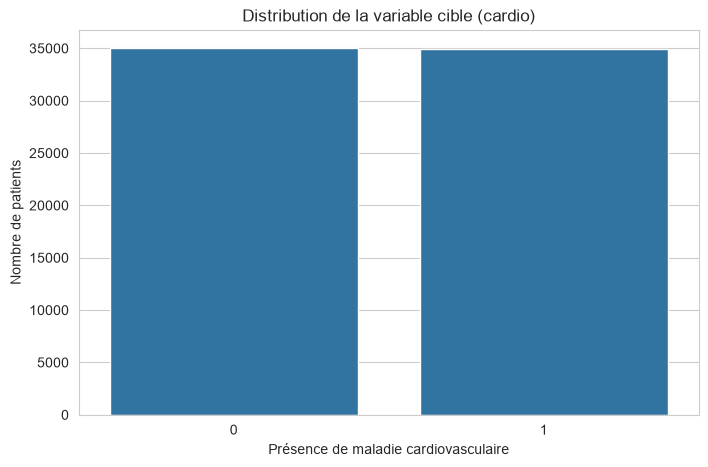

In [11]:
# Distribution de la variable cible (déséquilibre des classes) il n'y a pas de déséquilibre des classes, 
# la distribution est presque équilibrée.
print(df['cardio'].value_counts(normalize=True))

sns.countplot(data=df, x='cardio')
plt.title("Distribution de la variable cible (cardio)")
plt.xlabel("Présence de maladie cardiovasculaire")
plt.ylabel("Nombre de patients")
plt.show()


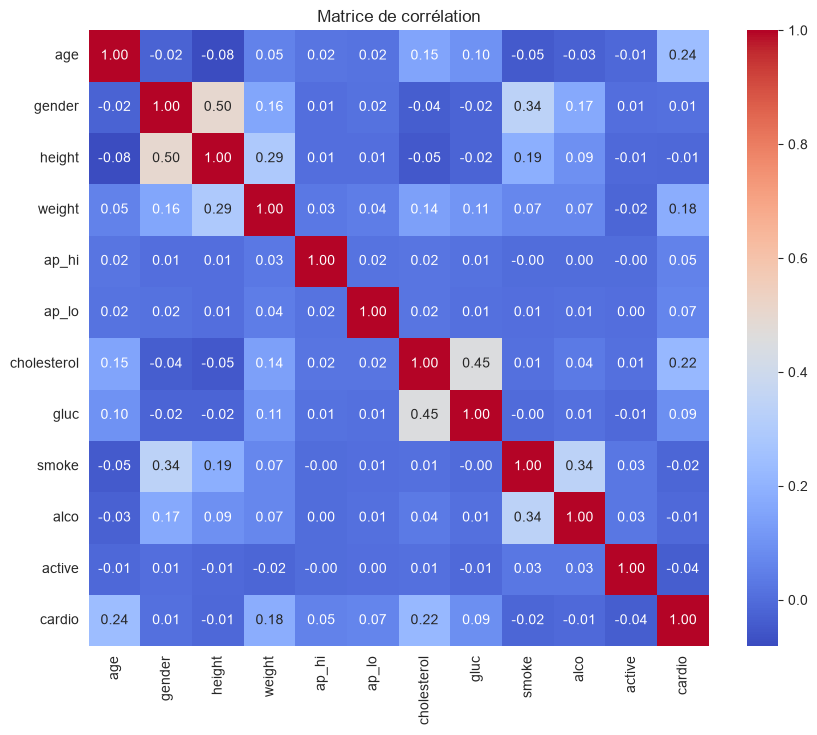

In [12]:
# Matrice de corrélation
"""Le point qui m'interpelle ici c'est: ap_hi et ap_lo (pression artérielle) ont une corrélation quasi nulle avec cardio, 
alors que cliniquement, la tension artérielle est l'un des facteurs de risque cardiovasculaire les plus importants. Ce n'est pas normal.
Pourquoi ? C'est le résultat direct des valeurs aberrantes qu'on a repérées dans le describe() 
(min=-150, max=16020 pour ap_hi). Ces valeurs extrêmes faussent le calcul du coefficient de corrélation (très sensible aux outliers) 
et « écrasent » la vraie relation entre pression artérielle et maladie cardiovasculaire."""
plt.figure(figsize=(10, 8))
sns.heatmap(df.drop(columns=['id']).corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Matrice de corrélation")
plt.show()


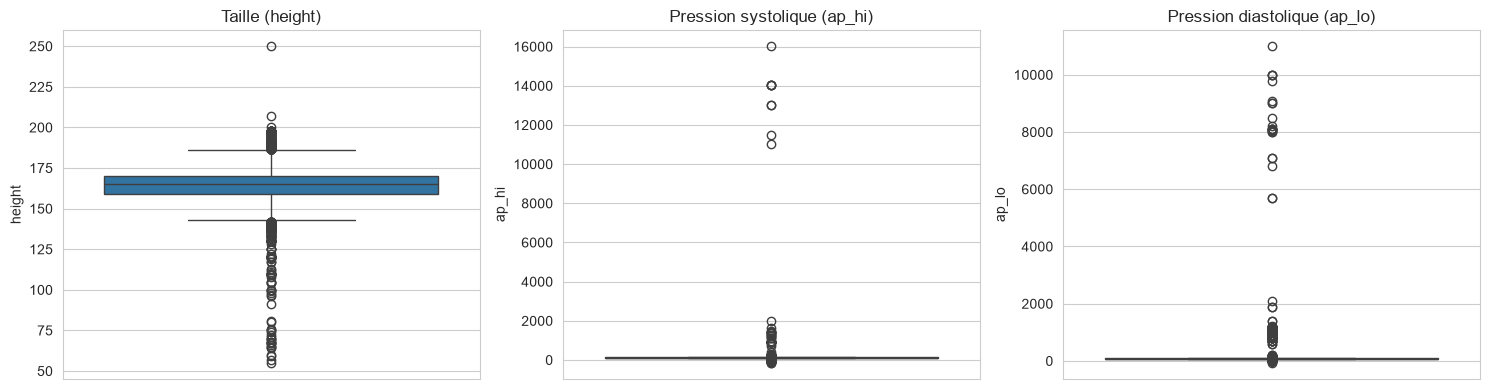

In [13]:
# Boxplots pour repérer les valeurs aberrantes sur les variables clés
# ap_hi C'est le plus frappant : la quasi-totalité des valeurs est écrasée près de 0 sur ce graphique, 
# avec quelques points aberrants qui montent jusqu'à ~16000. 
# Même phénomène : valeurs normales écrasées près de 0, avec des outliers jusqu'à ~10000-11000.
# mais elles sont moins extrêmes que pour la pression artérielle. 
# Taille(height) La boîte (75% des données) est resserrée entre ~155 et ~170 cm -
# cohérent. Mais on voit des points isolés qui descendent 
# jusqu'à 50 cm et montent jusqu'à 250 cm. Ce sont des outliers clairs, biologiquement impossibles pour un adulte.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(y=df['height'], ax=axes[0]).set_title("Taille (height)")
sns.boxplot(y=df['ap_hi'], ax=axes[1]).set_title("Pression systolique (ap_hi)")
sns.boxplot(y=df['ap_lo'], ax=axes[2]).set_title("Pression diastolique (ap_lo)")
plt.tight_layout()
plt.show()


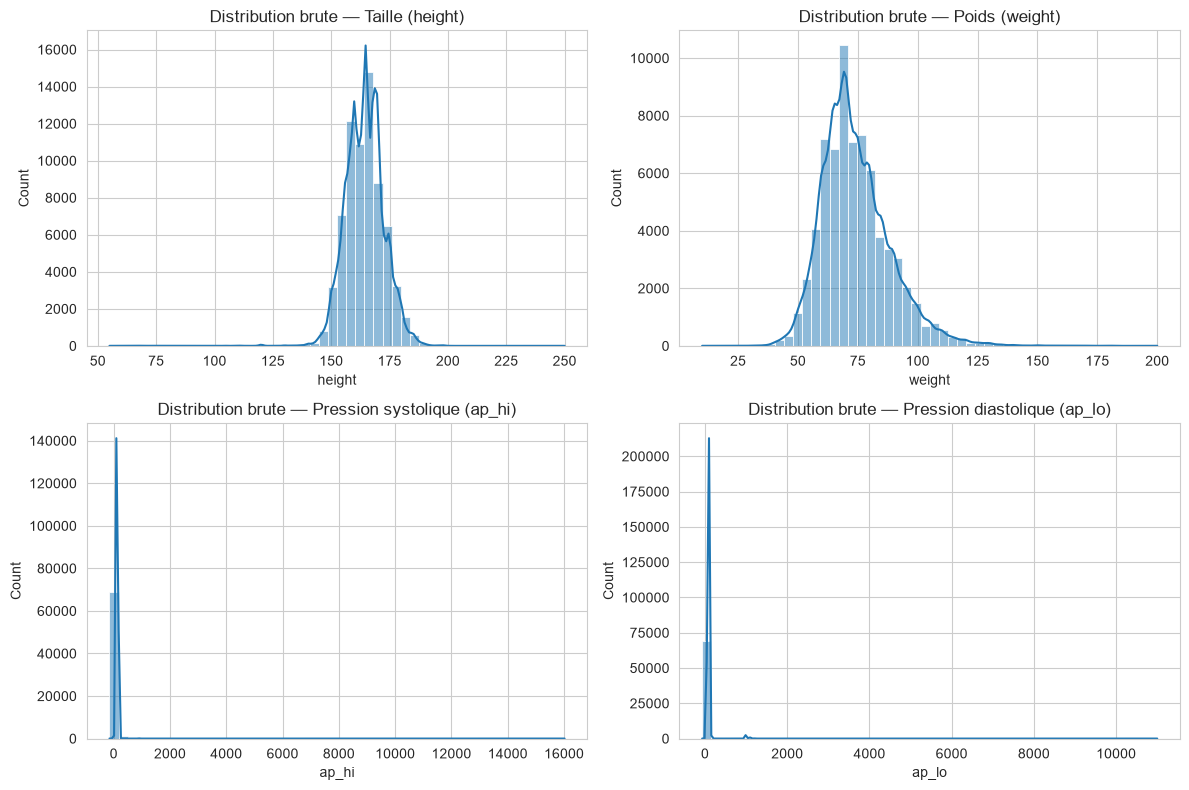

In [14]:
# Histogrammes des variables brutes (avant nettoyage)
"""ap_hi et ap_lo : exactement le problème anticipé — tout l'axe des abscisses 
est étiré jusqu'à 16000/11000 à cause de quelques valeurs extrêmes, ce qui écrase la vraie distribution 
(qui devrait ressembler à une cloche autour de 120/80) en une barre invisible près de 0. D'ou le nettoyage est indispensable 
 exactement ce qu'on avait prédit avec le describe() et les boxplots."""
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(df['height'], bins=50, kde=True, ax=axes[0,0])
axes[0,0].set_title("Distribution brute — Taille (height)")

sns.histplot(df['weight'], bins=50, kde=True, ax=axes[0,1])
axes[0,1].set_title("Distribution brute — Poids (weight)")

sns.histplot(df['ap_hi'], bins=50, kde=True, ax=axes[1,0])
axes[1,0].set_title("Distribution brute — Pression systolique (ap_hi)")

sns.histplot(df['ap_lo'], bins=50, kde=True, ax=axes[1,1])
axes[1,1].set_title("Distribution brute — Pression diastolique (ap_lo)")

plt.tight_layout()
plt.show()

## Étape 3 - Nettoyage & prétraitement

- Suppression des doublons
- Correction des valeurs biologiquement impossibles (pression artérielle négative ou aberrante, taille < 100 cm)
- Conversion de l'âge de jours en années



In [15]:
#Pour ces variables précises (height, weight, ap_hi, ap_lo), 
# une valeur comme ap_hi = 16020 ou height = 55 n'est pas juste "extrême"  c'est une 
# valeur impossible/une erreur de saisie (probablement une virgule oubliée, un chiffre en trop tapé par erreur).
#  On n'a aucun moyen fiable de deviner la vraie valeur derrière l'erreur.
#  Corriger à l'aveugle reviendrait à inventer une donnée.
df_clean = df.copy()

# Suppression des doublons
before = len(df_clean)
df_clean = df_clean.drop_duplicates()
print(f"Doublons supprimés : {before - len(df_clean)}")

# Conversion de l'âge (jours en années)
df_clean['age'] = (df_clean['age'] / 365.25).round(1)

# Suppression des valeurs biologiquement impossibles
before = len(df_clean)
df_clean = df_clean[
    (df_clean['height'] >= 100) & (df_clean['height'] <= 220) &
    (df_clean['weight'] >= 30) & (df_clean['weight'] <= 200) &
    (df_clean['ap_hi'] > 0) & (df_clean['ap_hi'] <= 250) &
    (df_clean['ap_lo'] > 0) & (df_clean['ap_lo'] <= 200) &
    (df_clean['ap_hi'] >= df_clean['ap_lo'])
]
print(f"Lignes supprimées (valeurs aberrantes) : {before - len(df_clean)}")
print(f"Dimensions finales : {df_clean.shape}")


Doublons supprimés : 0
Lignes supprimées (valeurs aberrantes) : 1323
Dimensions finales : (68677, 13)


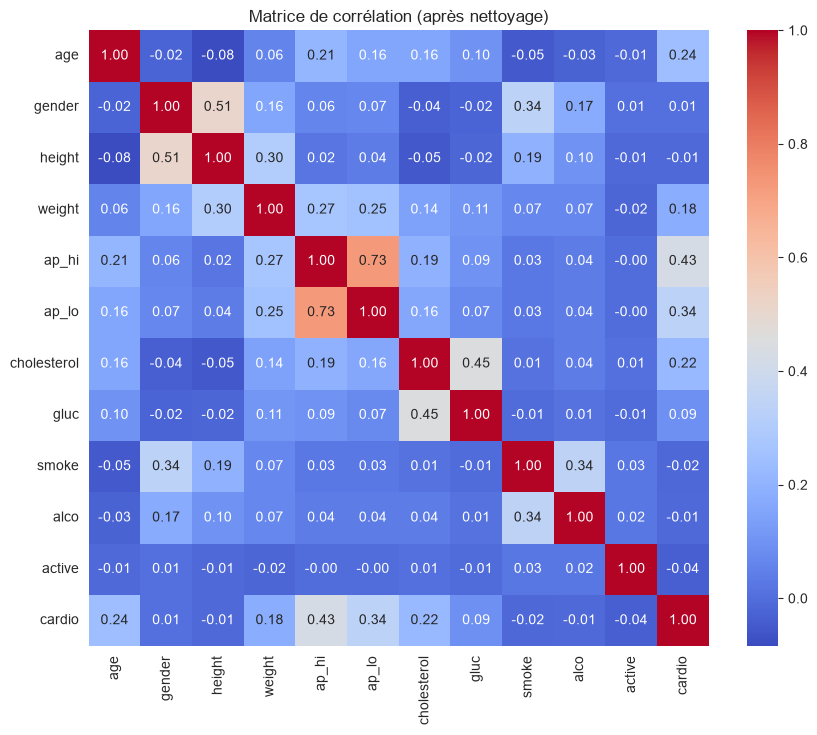

In [16]:
# Après nettoyage, on peut recalculer la matrice de corrélation pour voir 
# si la relation entre pression artérielle et maladie cardiovasculaire est plus cohérente. et note que la corrélation
#  entre ap_hi et ap_lo est maintenant très forte , ce qui est attendu.
plt.figure(figsize=(10, 8))
sns.heatmap(df_clean.drop(columns=['id']).corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Matrice de corrélation (après nettoyage)")
plt.show()

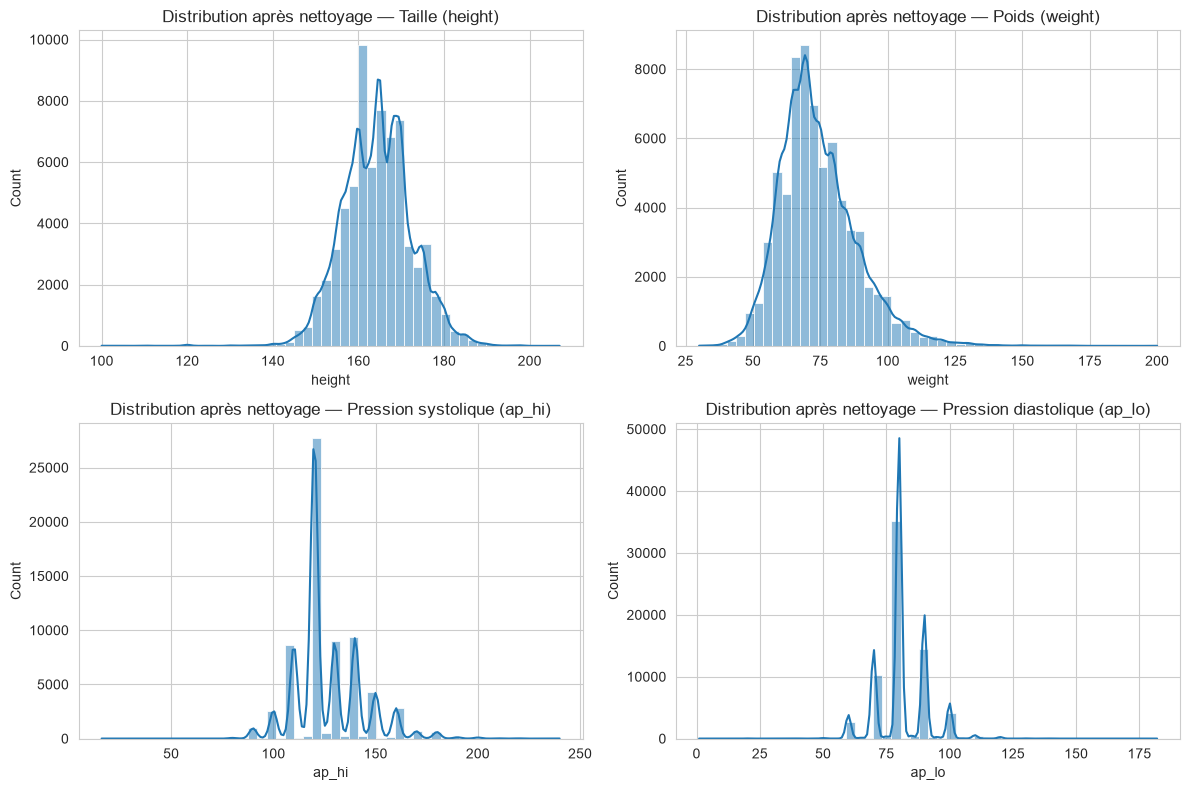

In [17]:
# Histogrammes des variables (après nettoyage)
"""Après nettoyage, les distributions sont plus cohérentes et ressemblent à ce qu'on attendrait cliniquement."""
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(df_clean['height'], bins=50, kde=True, ax=axes[0,0])
axes[0,0].set_title("Distribution après nettoyage — Taille (height)")

sns.histplot(df_clean['weight'], bins=50, kde=True, ax=axes[0,1])
axes[0,1].set_title("Distribution après nettoyage — Poids (weight)")

sns.histplot(df_clean['ap_hi'], bins=50, kde=True, ax=axes[1,0])
axes[1,0].set_title("Distribution après nettoyage — Pression systolique (ap_hi)")

sns.histplot(df_clean['ap_lo'], bins=50, kde=True, ax=axes[1,1])
axes[1,1].set_title("Distribution après nettoyage — Pression diastolique (ap_lo)")

plt.tight_layout()
plt.show()

## Étape 4 Feature Engineering

- **IMC** = poids / taille²
- **Pression pulsée** = ap_hi - ap_lo
- **Catégorisation de l'âge**


In [18]:
# IMC (Indice de Masse Corporelle)
df_clean['imc'] = df_clean['weight'] / ((df_clean['height'] / 100) ** 2)

# Pression pulsée
df_clean['pression_pulsee'] = df_clean['ap_hi'] - df_clean['ap_lo']

# Catégorisation de l'âge
df_clean['age_cat'] = pd.cut(
    df_clean['age'],
    bins=[0, 40, 50, 60, 100],
    labels=['<40', '40-50', '50-60', '60+']
)

df_clean[['age', 'imc', 'pression_pulsee', 'age_cat']].head()


,age,imc,pression_pulsee,age_cat
0,50.4,21.967120,30,50-60
1,55.4,34.927679,50,50-60
2,51.6,23.507805,60,50-60
3,48.2,28.710479,50,40-50
4,47.8,23.011177,40,40-50


In [19]:
# Filtrage des IMC physiologiquement impossibles
before = len(df_clean)
df_clean = df_clean[(df_clean['imc'] >= 12) & (df_clean['imc'] <= 60)]
print(f"Lignes supprimées (IMC aberrant) : {before - len(df_clean)}")

Lignes supprimées (IMC aberrant) : 37


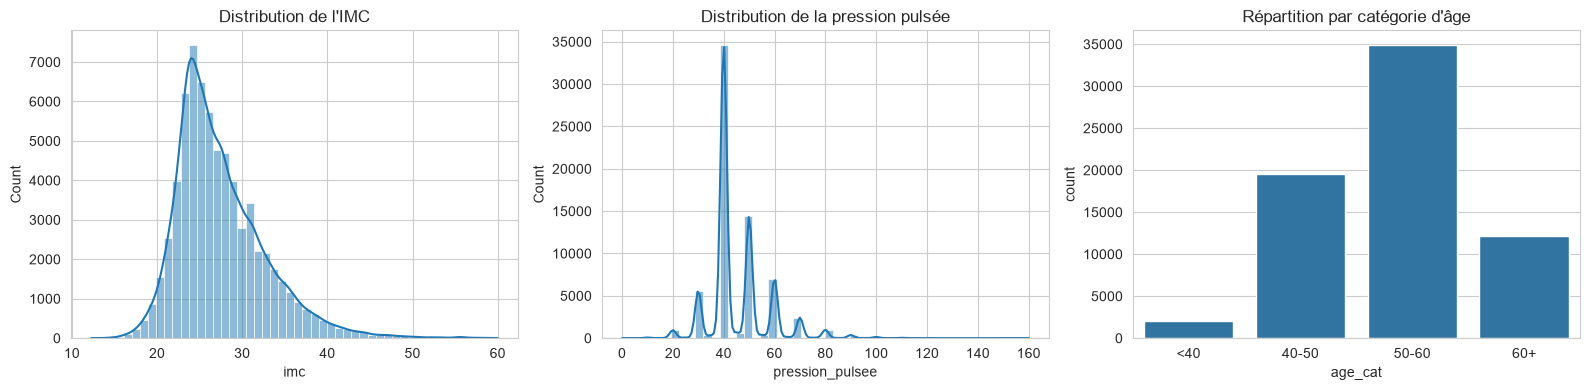

In [20]:
# Histogrammes des nouvelles variables créées
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(df_clean['imc'], bins=50, kde=True, ax=axes[0])
axes[0].set_title("Distribution de l'IMC")

sns.histplot(df_clean['pression_pulsee'], bins=50, kde=True, ax=axes[1])
axes[1].set_title("Distribution de la pression pulsée")

sns.countplot(data=df_clean, x='age_cat', order=['<40', '40-50', '50-60', '60+'], ax=axes[2])
axes[2].set_title("Répartition par catégorie d'âge")

plt.tight_layout()
plt.show()

## Étape 5 Gestion du déséquilibre des classes

Le dataset cardiovasculaire est relativement équilibré (~50/50). On applique donc `class_weight='balanced'` dans les algorithmes plutôt qu'un rééchantillonnage type SMOTE (réservé au dataset PaySim, fortement déséquilibré).


In [21]:
print(df_clean['cardio'].value_counts(normalize=True))


cardio
0    0.505288
1    0.494712
Name: proportion, dtype: float64


## Étape 6 Normalisation et séparation train/test

In [22]:
features = ['age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo',
            'cholesterol', 'gluc', 'smoke', 'alco', 'active',
            'imc', 'pression_pulsee']
target = 'cardio'

X = df_clean[features]
y = df_clean[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Train : {X_train.shape}, Test : {X_test.shape}")


Train : (54912, 13), Test : (13728, 13)


## Étape 7 — Modélisation : Détection d'anomalies

### Algorithmes supervisés : Random Forest, XGBoost, Régression logistique


In [23]:
models = {}

# Régression logistique (baseline)
log_reg = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=RANDOM_STATE)
log_reg.fit(X_train_scaled, y_train)
models['Régression Logistique'] = log_reg

# Random Forest
rf = RandomForestClassifier(class_weight='balanced', n_estimators=200, random_state=RANDOM_STATE)
rf.fit(X_train_scaled, y_train)
models['Random Forest'] = rf

# XGBoost
xgb_clf = xgb.XGBClassifier(
    n_estimators=200, use_label_encoder=False, eval_metric='logloss',
    random_state=RANDOM_STATE
)
xgb_clf.fit(X_train_scaled, y_train)
models['XGBoost'] = xgb_clf

print("Modèles supervisés entraînés :", list(models.keys()))


c:\Users\agnes\Downloads\venv_pfe\Lib\site-packages\xgboost\training.py:200: UserWarning: [02:12:32] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Modèles supervisés entraînés : ['Régression Logistique', 'Random Forest', 'XGBoost']


### Algorithmes non supervisés : Isolation Forest, Local Outlier Factor, Autoencoder

In [24]:
# Isolation Forest
contamination_rate = y_train.mean()  # proportion approximative d'anomalies

iso_forest = IsolationForest(contamination=contamination_rate, random_state=RANDOM_STATE)
iso_forest.fit(X_train_scaled)
# Isolation Forest retourne -1 (anomalie) / 1 (normal) -> on convertit en 0/1
iso_pred_test = np.where(iso_forest.predict(X_test_scaled) == -1, 1, 0)


In [25]:
# Local Outlier Factor (novelty=True permet le predict sur de nouvelles données)
lof = LocalOutlierFactor(n_neighbors=20, contamination=contamination_rate, novelty=True)
lof.fit(X_train_scaled)
lof_pred_test = np.where(lof.predict(X_test_scaled) == -1, 1, 0)


In [26]:

!pip install keras


[notice] A new release of pip is available: 24.0 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [27]:
import sys
!{sys.executable} -m pip install tensorflow


[notice] A new release of pip is available: 24.0 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [28]:
!pip install shap
!pip install imbalanced-learn
!pip install layers


[notice] A new release of pip is available: 24.0 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 24.0 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip


  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
  Created wheel for layers: filename=layers-0.1.5-py3-none-any.whl size=5388 sha256=30651f974b0f668e7b4372c6099865563a583adc388ef049f75c47c98cf2a10b
  Stored in directory: c:\users\agnes\appdata\local\pip\cache\wheels\36\2f\17\808a8b9187247bb31ffb720b3a8ba0b8a90bd766160f148740
  Created wheel for bashutils: filename=Bashutils-0.0.4-py3-none-any.whl size=5484 sha256=b2299ad4609e57d0f05e5f10cce0b03ecb05a100098a96cddc64ca985e05d533
  Stored in directory: c:\users\agnes\appdata\local\pip\cache\wheels\a8\90\52\eec0445722a0f747ad367ebb29872952557bf84d9db948328a
Successfully built layers bashutils



[notice] A new release of pip is available: 24.0 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip


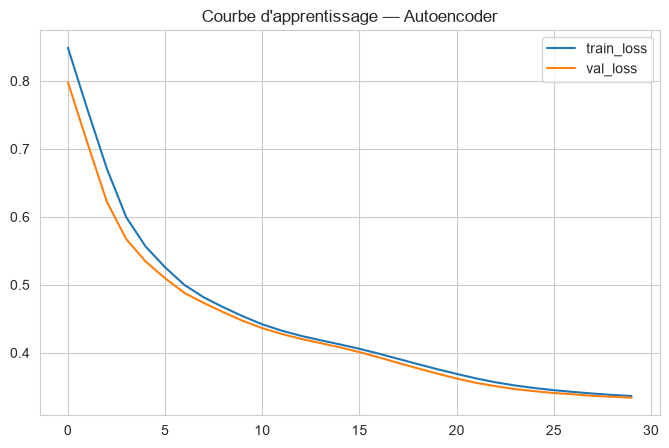

In [29]:
# Autoencoder (Keras/TensorFlow)
from tensorflow import keras
from tensorflow.keras import layers

# Entraîné uniquement sur les patients sains pour apprendre le profil "normal"
X_train_normal = X_train_scaled[y_train.values == 0]

input_dim = X_train_scaled.shape[1]
encoding_dim = max(2, input_dim // 2)

autoencoder = keras.Sequential([
    layers.Input(shape=(input_dim,)),
    layers.Dense(encoding_dim, activation='relu'),
    layers.Dense(max(2, encoding_dim // 2), activation='relu'),
    layers.Dense(encoding_dim, activation='relu'),
    layers.Dense(input_dim, activation='linear'),
])
autoencoder.compile(optimizer='adam', loss='mse')

history = autoencoder.fit(
    X_train_normal, X_train_normal,
    epochs=30, batch_size=256, shuffle=True,
    validation_split=0.1, verbose=0
)

# Erreur de reconstruction -> seuil basé sur le quantile du train
reconstructions = autoencoder.predict(X_test_scaled, verbose=0)
mse = np.mean(np.power(X_test_scaled - reconstructions, 2), axis=1)
threshold = np.quantile(mse, 1 - contamination_rate)
autoencoder_pred_test = (mse > threshold).astype(int)

plt.plot(history.history['loss'], label='train_loss')
plt.plot(history.history['val_loss'], label='val_loss')
plt.legend(); plt.title("Courbe d'apprentissage — Autoencoder"); plt.show()


## Étape 8 Évaluation et comparaison des modèles

Métriques utilisées (l'accuracy seule est insuffisante pour un problème avec déséquilibre potentiel) : **F1-score**, **AUC-ROC**, **matrice de confusion**, **précision/rappel.


In [30]:
results = []

# Modèles supervisés (proba disponible)
for name, model in models.items():
    y_pred = model.predict(X_test_scaled)
    y_proba = model.predict_proba(X_test_scaled)[:, 1]
    results.append({
        'Algorithme': name,
        'Précision': precision_score(y_test, y_pred),
        'Rappel': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred),
        'AUC-ROC': roc_auc_score(y_test, y_proba)
    })

# Modèles non supervisés (pas de proba continue standard -> AUC basé sur le score de décision)
results.append({
    'Algorithme': 'Isolation Forest',
    'Précision': precision_score(y_test, iso_pred_test),
    'Rappel': recall_score(y_test, iso_pred_test),
    'F1-Score': f1_score(y_test, iso_pred_test),
    'AUC-ROC': roc_auc_score(y_test, -iso_forest.decision_function(X_test_scaled))
})

results.append({
    'Algorithme': 'Local Outlier Factor',
    'Précision': precision_score(y_test, lof_pred_test),
    'Rappel': recall_score(y_test, lof_pred_test),
    'F1-Score': f1_score(y_test, lof_pred_test),
    'AUC-ROC': roc_auc_score(y_test, -lof.decision_function(X_test_scaled))
})

results.append({
    'Algorithme': 'Autoencoder',
    'Précision': precision_score(y_test, autoencoder_pred_test),
    'Rappel': recall_score(y_test, autoencoder_pred_test),
    'F1-Score': f1_score(y_test, autoencoder_pred_test),
    'AUC-ROC': roc_auc_score(y_test, mse)
})

results_df = pd.DataFrame(results).sort_values('F1-Score', ascending=False)
results_df


,Algorithme,Précision,Rappel,F1-Score,AUC-ROC
2,XGBoost,0.737856,0.682226,0.708952,0.785652
0,Régression Logistique,0.742209,0.669857,0.704180,0.788502
1,Random Forest,0.703137,0.703137,0.703137,0.769172
5,Autoencoder,0.594817,0.594905,0.594861,0.634333
3,Isolation Forest,0.564939,0.571344,0.568124,0.605125
4,Local Outlier Factor,0.513408,0.541305,0.526987,0.519899


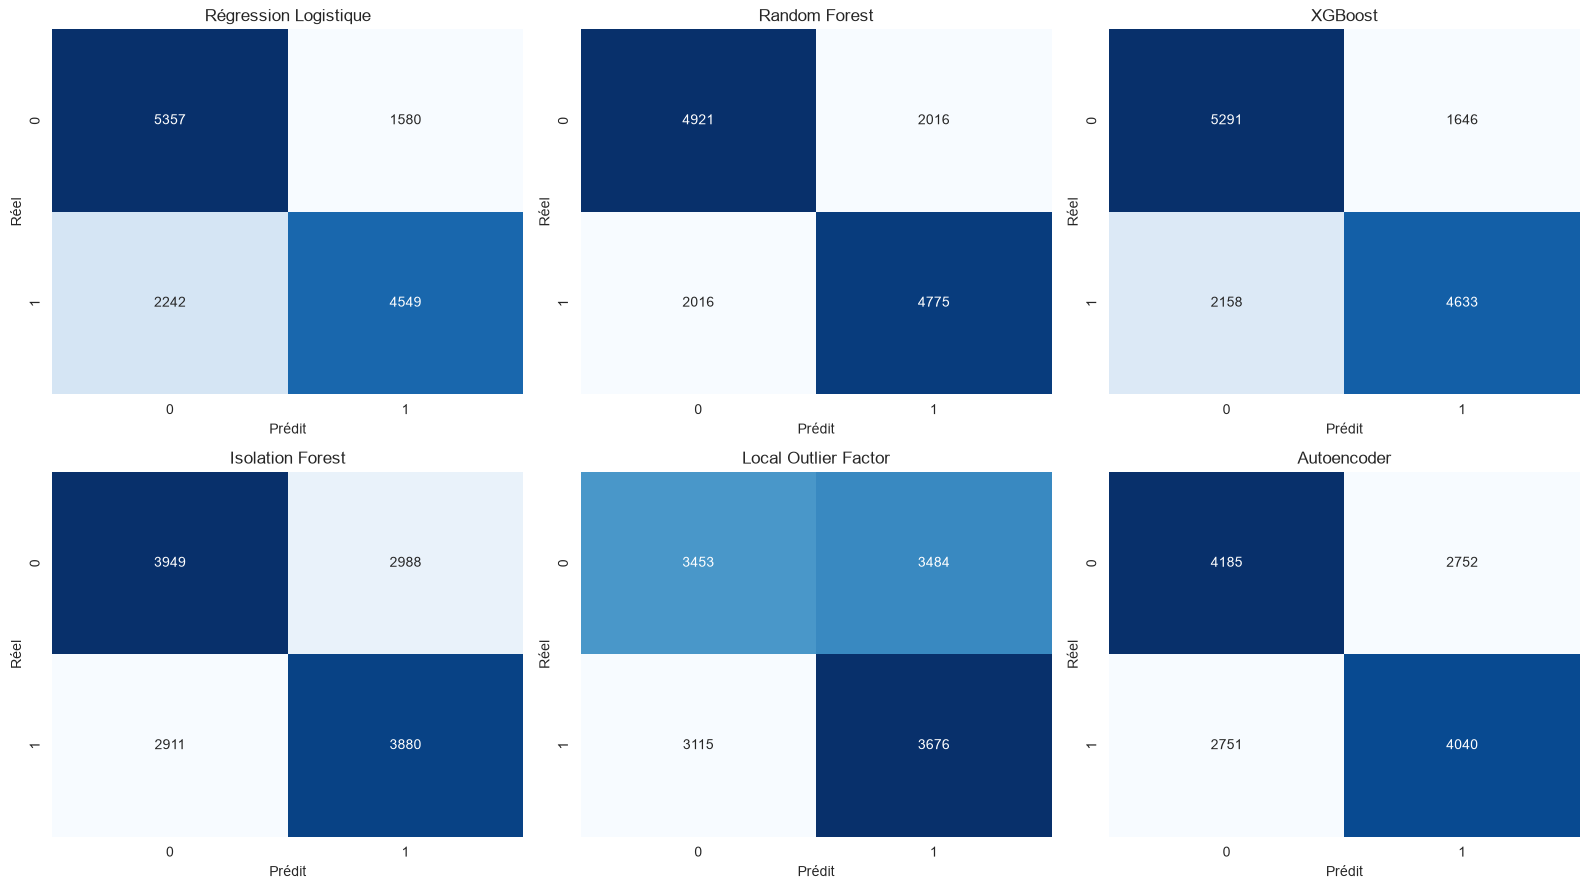

In [31]:
# Matrices de confusion pour chaque modèle
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
preds_dict = {
    'Régression Logistique': models['Régression Logistique'].predict(X_test_scaled),
    'Random Forest': models['Random Forest'].predict(X_test_scaled),
    'XGBoost': models['XGBoost'].predict(X_test_scaled),
    'Isolation Forest': iso_pred_test,
    'Local Outlier Factor': lof_pred_test,
    'Autoencoder': autoencoder_pred_test,
}

for ax, (name, pred) in zip(axes.flatten(), preds_dict.items()):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False)
    ax.set_title(name)
    ax.set_xlabel('Prédit'); ax.set_ylabel('Réel')

plt.tight_layout()
plt.show()


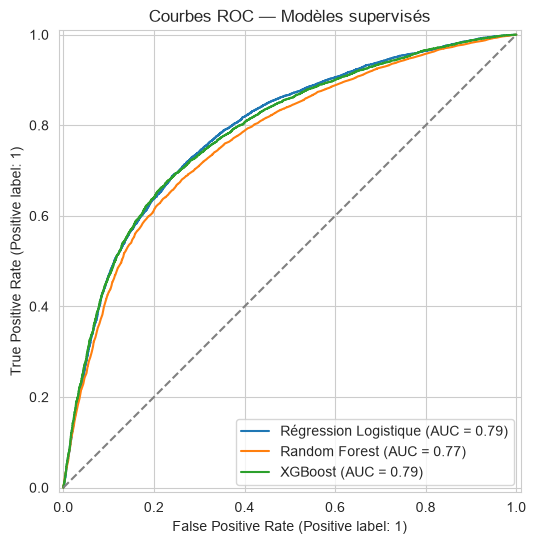

In [32]:
# Courbes ROC (modèles supervisés)
fig, ax = plt.subplots(figsize=(7, 6))
for name, model in models.items():
    RocCurveDisplay.from_estimator(model, X_test_scaled, y_test, ax=ax, name=name)
plt.title("Courbes ROC — Modèles supervisés")
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.show()


## Étape 9 — Interprétabilité (XAI)

- Importance des variables (Random Forest, XGBoost)
- Valeurs SHAP pour expliquer les prédictions du meilleur modèle


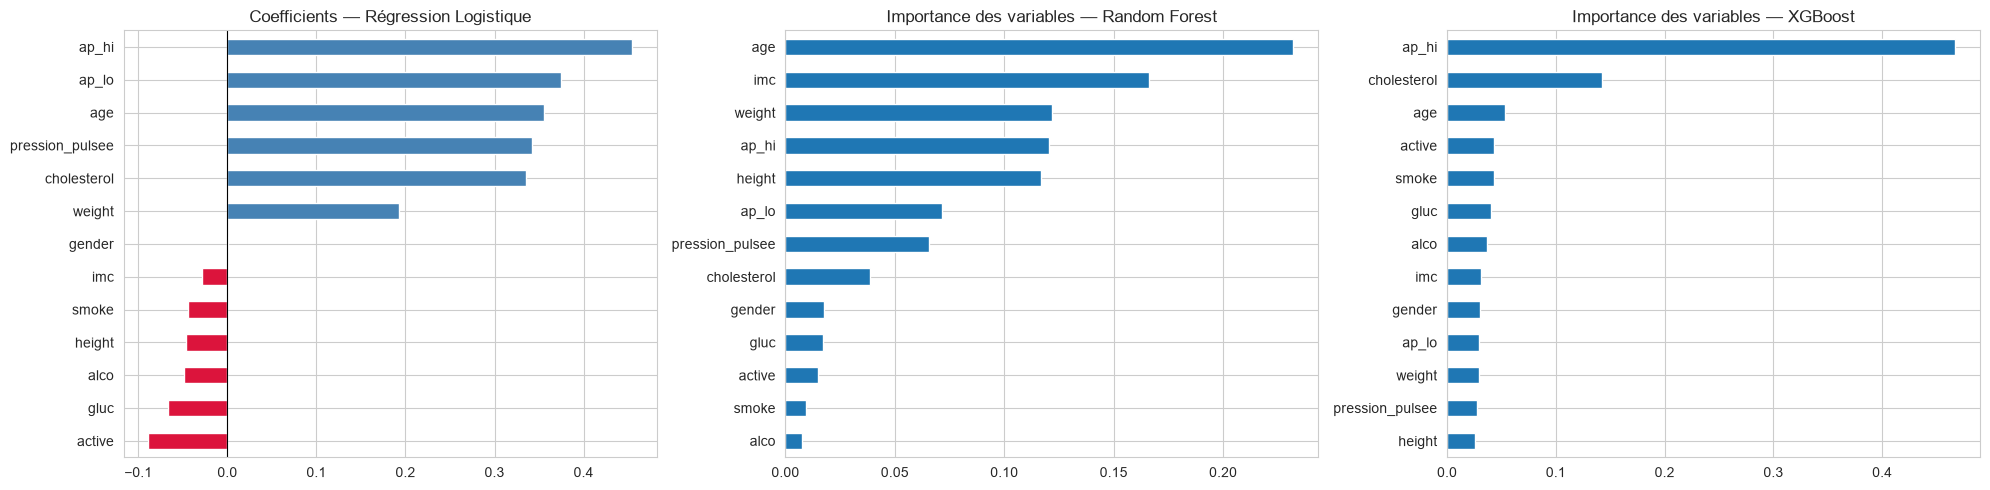

In [33]:
# Importance des variables
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# Régression Logistique : coefficients (le signe indique le sens de l'effet)
log_reg_coefs = pd.Series(models['Régression Logistique'].coef_[0], index=features).sort_values()
colors = ['crimson' if c < 0 else 'steelblue' for c in log_reg_coefs]
log_reg_coefs.plot(kind='barh', ax=axes[0], color=colors, title="Coefficients — Régression Logistique")
axes[0].axvline(0, color='black', linewidth=0.8)

# Random Forest : importance des variables
rf_importances = pd.Series(models['Random Forest'].feature_importances_, index=features).sort_values()
rf_importances.plot(kind='barh', ax=axes[1], title="Importance des variables — Random Forest")

# XGBoost : importance des variables
xgb_importances = pd.Series(models['XGBoost'].feature_importances_, index=features).sort_values()
xgb_importances.plot(kind='barh', ax=axes[2], title="Importance des variables — XGBoost")

plt.tight_layout()
plt.show()


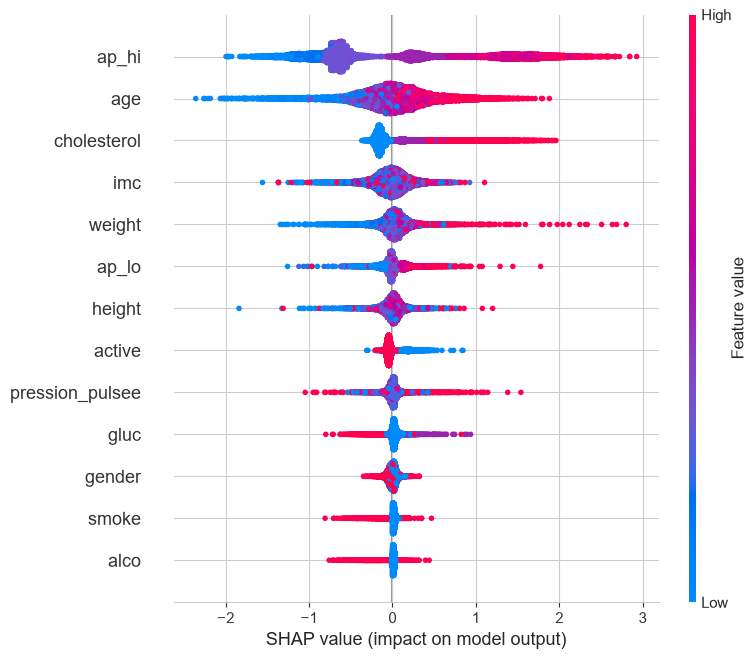

In [34]:
import shap

# Explication SHAP pour le meilleur modèle supervisé (ex: XGBoost)
explainer = shap.TreeExplainer(models['XGBoost'])
shap_values = explainer.shap_values(X_test_scaled)

shap.summary_plot(shap_values, X_test, feature_names=features, show=True)


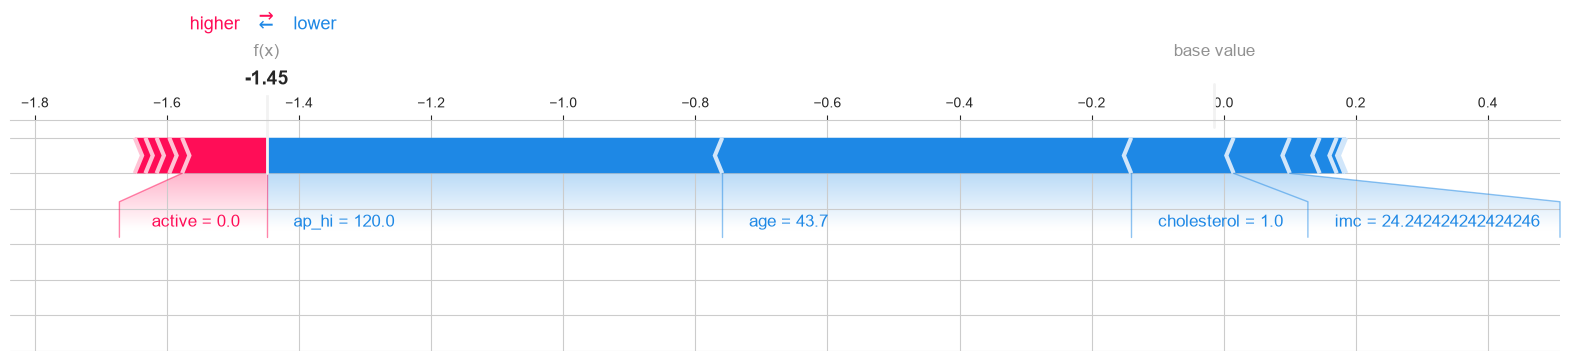

In [35]:
# Force plot pour une observation individuelle (exemple : le premier patient du set de test)
shap.initjs()
shap.force_plot(
    explainer.expected_value, shap_values[0, :], X_test.iloc[0, :],
    matplotlib=True, show=True
)


## Étape 10 — Automatisation du pipeline

Construction d'un `Pipeline` scikit-learn enchaînant prétraitement + meilleur modèle, puis export via `joblib` pour réutilisation sur de nouvelles données.


In [36]:
# Sélection du meilleur modèle (F1-score le plus élevé parmi les modèles supervisés)
best_model_name = results_df.iloc[0]['Algorithme']
print(f"Meilleur modèle : {best_model_name}")

best_model = models.get(best_model_name, models['Random Forest'])  # fallback si non supervisé en tête

final_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', best_model)
])

final_pipeline.fit(X_train, y_train)


Meilleur modèle : XGBoost


c:\Users\agnes\Downloads\venv_pfe\Lib\site-packages\xgboost\training.py:200: UserWarning: [02:14:08] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['age','gender','height',...,'active','imc','pression_pulsee']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [37]:
# Export du pipeline entraîné
joblib.dump(final_pipeline, 'pipeline_cardio.pkl')
print("Pipeline exporté sous 'pipeline_cardio.pkl'")

# Exemple de réutilisation :
# loaded_pipeline = joblib.load('pipeline_cardio.pkl')
# loaded_pipeline.predict(nouvelles_donnees)


Pipeline exporté sous 'pipeline_cardio.pkl'


In [38]:
import os
print(os.path.exists('pipeline_cardio.pkl'))  # doit afficher True
print(os.path.getsize('pipeline_cardio.pkl'), "octets")  # taille du fichier

True
705954 octets


In [39]:
import joblib
loaded_pipeline = joblib.load('pipeline_cardio.pkl')

# Prédire sur un nouveau patient (mêmes colonnes que features)
nouvelle_donnee = X_test.iloc[[0]]  # exemple
prediction = loaded_pipeline.predict(nouvelle_donnee)
print(prediction)  # 0 ou 1

[0]


In [40]:
pip install -r requirements.txt


Note: you may need to restart the kernel to use updated packages.


ERROR: Could not open requirements file: [Errno 2] No such file or directory: 'requirements.txt'

[notice] A new release of pip is available: 24.0 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## Conclusion

Ce notebook a couvert l'ensemble du pipeline pour le dataset cardiovasculaire : ingestion, EDA, nettoyage, feature engineering, gestion du déséquilibre, modélisation (3 algorithmes supervisés + 3 non supervisés), évaluation comparative et interprétabilité via SHAP. Le pipeline final est exporté et prêt à être réutilisé.

Ce notebook constitue le **Livrable 1** (notebook cardiovasculaire) du projet. Le tableau `results_df` alimente directement le **Livrable 5** (tableau comparatif des modèles).
